# 03 · Wie finden wir die Suva-Fälle besser? Ähnlichkeit, gelernter Score und Apertus

**Fragen**
1. Was ist besser: **nur Ähnlichkeit** (Abis Vector-DB-Score) oder **Ähnlichkeit + Apertus-Score**?
2. Wie bekommen die Urteile, die Suva wirklich zusammenfasst, einen **hohen Score**?

**Messung wie in `results/eval.md` (Issue #21):** Testquartal Q1/2026 (2004 Urteile, 31 Suva-Fälle). Jede Methode darf nur Wissen von **vor** 2026 nutzen.
Entscheidungen (Prompt, Gewichte) werden auf **Q4/2025** getroffen und erst dann auf Q1/2026 geprüft.

**Drei Bausteine**

| Baustein | Idee | Kosten |
|---|---|---|
| **Ähnlichkeit** (heute, Abi) | Wie ähnlich ist ein Urteil den bisherigen Suva-Fällen? + Bonus für 8C / Unfall / UVG im Text | gratis, gespeicherte Vektoren |
| **Gelernter Score** (neu) | Ein kleines Modell lernt aus *allen* bisherigen Urteilen: welche hat Suva zusammengefasst, welche nicht? | gratis, 1 Sekunde Training |
| **Apertus** | Apertus liest Auszug + ähnlichste Suva-Fälle und gibt 0–100 + Begründung (Prompt der Triage) | 1 Gateway-Aufruf pro Urteil, nur für die Vorauswahl |

Rechenlogik: `src/hack_apertus_coffee_exe/eval/learned.py` und `eval/relevance.py`. Tests: `tests/test_eval_learned.py`.


In [1]:
import os
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from hack_apertus_coffee_exe.eval.learned import (
    PROMPT_V2, DecisionCache, ask_apertus, combine, learned_scores,
)
from hack_apertus_coffee_exe.eval.relevance import (
    Corpus, open_vectordb, recall_curve, score_period, subject_area, summary_row, to_scored_cases,
)

pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 120)
BLUE, ORANGE, AQUA, GRAY, INK = "#257de0", "#f47230", "#00b894", "#9c9c9c", "#191919"

# False = nur gespeicherte Apertus-Antworten lesen (results/tables/apertus_*.jsonl), kein Gateway-Aufruf.
RUN_APERTUS = False

db = open_vectordb()
corpus = Corpus(db)
Q4 = dict(date_from="2025-10-01", date_to="2025-12-31", ref_date_from="2025-07-01", ref_date_to="2025-09-30")
Q1 = dict(date_from="2026-01-01", date_to="2026-03-31", ref_date_from="2025-10-01", ref_date_to="2025-12-31")

def apertus(version, quarter):
    rows = DecisionCache(f"results/tables/apertus_{version}_scores_{quarter}.jsonl").rows
    return {k: r["apertus_score"] for k, r in rows.items()}

COLS = ["F2", "Recall@30", "Recall@100", "Ausgewählt für 90 % Recall", "Ausgewählt für 100 % Recall"]

In [2]:
# Nur nötig, wenn Antworten fehlen (RUN_APERTUS = True): Vorauswahl bewerten lassen, ~250 Aufrufe à ~1 s.
if RUN_APERTUS:
    from hack_apertus_coffee_exe.triage.llm import ApertusTriageClient
    from hack_apertus_coffee_exe.triage.reference_corpus import load_reference_corpus
    client, refs = ApertusTriageClient(), {r.case_id: r for r in load_reference_corpus("judgements")}
    q4 = db.score_candidates(**Q4)
    q1 = db.score_candidates(**Q1)
    short4 = [r["doc_key"] for r in q4[:200]]
    lrn = learned_scores(corpus, date_from=Q1["date_from"], date_to=Q1["date_to"])
    short1 = list(dict.fromkeys([r["doc_key"] for r in q1[:200]] + lrn.doc_key[:200].tolist()))
    for version, prompt in (("v1", None), ("v2", PROMPT_V2)):
        ask_apertus(short4, {r["doc_key"]: r["similar_cases"] for r in q4},
                    DecisionCache(f"results/tables/apertus_{version}_scores_q4_2025.jsonl"),
                    client=client, references=refs, system_prompt=prompt)
        ask_apertus(short1, {r["doc_key"]: r["similar_cases"] for r in q1},
                    DecisionCache(f"results/tables/apertus_{version}_scores_q1_2026.jsonl"),
                    client=client, references=refs, system_prompt=prompt)

## 1. Gelernter Score: aus Suvas Entscheidungen lernen

Die Ähnlichkeit fragt nur: „Sieht das Urteil aus wie ein Suva-Fall?“ Sie weiss nicht, dass Suva **rund die Hälfte der Unfall-Urteile *nicht* zusammenfasst**.
Der gelernte Score bekommt alle Urteile vor 2026 als Beispiele: Suva-Fall = 1, alle anderen = 0. Daraus lernt eine logistische Regression,
welche Merkmale (zentrierte Embeddings + Kammer 8C / Unfall im Sachgebiet / UVG im Text) Suva-Fälle wirklich ausmachen.

- Training: alle Urteile bis 31.12.2025 (davon 51 Suva-Fälle). Test: Q1/2026. Kein Leakage.
- Keine neue Bibliothek, nur numpy. Training dauert etwa 1 Sekunde.


In [3]:
abi_q1 = score_period(corpus, centre=False, **Q1)                     # = Abis Score (siehe Notebook 02, identisch)
learned_q1 = learned_scores(corpus, date_from=Q1["date_from"], date_to=Q1["date_to"])

pd.DataFrame([summary_row("Ähnlichkeit (heute, Abi)", to_scored_cases(abi_q1)),
              summary_row("Gelernter Score", to_scored_cases(learned_q1))]).set_index("Variante")[COLS]

,F2,Recall@30,Recall@100,Ausgewählt für 90 % Recall,Ausgewählt für 100 % Recall
Variante,,,,,
"Ähnlichkeit (heute, Abi)",0.661,0.484,0.839,114,1847
Gelernter Score,0.651,0.516,0.903,100,243


**Wichtigster Unterschied: die letzte Spalte.** Um *alle* 31 Suva-Fälle zu finden, müsste Suva mit dem heutigen Score 1847 Urteile anschauen,
mit dem gelernten Score nur noch 243. Grund: Die Invalidenversicherungs-Fälle (9C), die Suva auch zusammenfasst, landen nicht mehr ganz hinten.


In [4]:
ranks = pd.DataFrame({
    "heute": abi_q1[abi_q1.is_reference].set_index("case_id")["rank"],
    "gelernt": learned_q1[learned_q1.is_reference].set_index("case_id")["rank"],
}).join(abi_q1.set_index("case_id")["subject"].str[:50]).sort_values("heute")
ranks.tail(8)   # die 8 Suva-Fälle, die heute am schlechtesten platziert sind: Rang heute vs. gelernt

,heute,gelernt,subject
case_id,,,
8C_377/2025,79,78,Invalidenversicherung (Invalidenrente; Arbeitsunfä
8C_149/2025,82,77,Invalidenversicherung (Invalidenrente)
8C_272/2025,85,55,Invalidenversicherung (Invalidenrente)
8C_450/2025,104,86,Invalidenversicherung (Invalidenrente; berufliche
8C_314/2025,114,100,Assurance-invalidité (allocation pour impotent)
9C_311/2025,227,173,Invalidenversicherung
9C_145/2025,230,128,Invalidenversicherung
9C_65/2025,1847,243,Assicurazione per l'invalidità (diniego di giustiz


## 2. Apertus: Prompt v1 der Triage übersieht Invalidenversicherung

Apertus (8B) hat die Vorauswahl von Q1 bewertet: Top 200 nach Ähnlichkeit ∪ Top 200 nach gelerntem Score = 246 Urteile, davon 30 der 31 Suva-Fälle.
Prompt v1 ist der heutige Prompt aus `triage/llm.py`.


In [5]:
def score_overview(version, quarter):
    s = pd.Series(apertus(version, quarter)).dropna()
    is_suva = corpus.meta.loc[s.index, "is_reference"].astype(bool)
    return pd.Series({"bewertete Urteile": len(s), "verschiedene Score-Werte": s.nunique(),
                      "Ø Suva-Fälle": s[is_suva].mean(), "Ø andere": s[~is_suva].mean(),
                      "Suva-Fälle mit Score < 30": int((s[is_suva] < 30).sum())})

pd.DataFrame({"Prompt v1": score_overview("v1", "q1_2026"), "Prompt v2": score_overview("v2", "q1_2026")}).round(1)

,Prompt v1,Prompt v2
bewertete Urteile,245.0,246.0
verschiedene Score-Werte,3.0,7.0
Ø Suva-Fälle,79.2,90.5
Ø andere,20.3,55.2
Suva-Fälle mit Score < 30,5.0,0.0


In [6]:
v1_rows = DecisionCache("results/tables/apertus_v1_scores_q1_2026.jsonl").rows
pd.DataFrame([{"Fall": corpus.meta.at[k, "case_id"], "Sachgebiet": corpus.meta.at[k, "subject"][:45],
               "Apertus v1": r["apertus_score"], "Begründung von Apertus": r["reason"][:150]}
              for k, r in v1_rows.items() if corpus.meta.at[k, "is_reference"] and r.get("apertus_score") == 0])

,Fall,Sachgebiet,Apertus v1,Begründung von Apertus
0,8C_149/2025,Invalidenversicherung (Invalidenrente),0.0,"Das Urteil betrifft die Invalidenversicherung (Invalidenrente) und nicht die Unfallversicherung nach UVG/LAA, Berufs..."
1,8C_272/2025,Invalidenversicherung (Invalidenrente),0.0,Das Urteil betrifft die Invalidenversicherung (IVG/ATSG) und nicht die Unfallversicherung nach UVG/LAA. Es handelt s...
2,8C_450/2025,Invalidenversicherung (Invalidenrente; berufl,0.0,Das Urteil betrifft die Invalidenversicherung (IV) und nicht die Unfallversicherung nach UVG. Es geht um die Beweisk...
3,9C_145/2025,Invalidenversicherung,0.0,Das Urteil betrifft die Invalidenversicherung (IVG/ATSG) und nicht die Unfallversicherung nach UVG/LAA. Es handelt s...
4,9C_311/2025,Invalidenversicherung,0.0,"Das Urteil betrifft die Invalidenversicherung (IV) und nicht die Unfallversicherung nach UVG/LAA, Berufskrankheiten ..."


**Zwei Probleme mit Prompt v1:**
1. Er definiert Suva-Relevanz nur über die **Unfallversicherung**. Suva fasst aber auch **Invalidenversicherung** zusammen: 14 von 51 Suva-Fällen vor 2026, 8 von 31 in Q1.
   Apertus lehnt diese Fälle deshalb korrekt nach Prompt ab („betrifft IV, nicht UVG“).
2. Apertus antwortet fast nur mit **0 oder 95**, also ja/nein. Das hilft nicht beim Sortieren.

**Prompt v2** (`PROMPT_V2` in `eval/learned.py`) nimmt IV-Fragen mit UVG-Bezug auf (Invaliditätsbemessung, Einkommensvergleich, Gutachten, Revision)
und beschreibt die Skala 0–100 in Stufen. Beides ist **aus der Zeit vor 2026** abgeleitet.


## 3. Prüfung auf Q4/2025: v1 oder v2, und wie stark soll Apertus zählen?

Hier werden die Entscheidungen getroffen. Vorauswahl = Top 200 nach Ähnlichkeit (enthält alle 28 Suva-Fälle von Q4).
Gewicht 0 = nur Ähnlichkeit, Gewicht 1 = nur Apertus. Dazwischen wird gemischt wie `final_score` der Triage (dort heute 0.75).


In [7]:
abi_q4 = score_period(corpus, centre=False, **Q4)
rows = []
for version in ("v1", "v2"):
    for w in (0, 0.25, 0.5, 0.75, 1):
        rows.append({"Prompt": version, "Gewicht Apertus": w,
                     **summary_row("", to_scored_cases(combine(abi_q4, apertus(version, "q4_2025"), w)))})
validation = pd.DataFrame(rows).set_index(["Prompt", "Gewicht Apertus"])[COLS[:-1]]
validation

F2  Recall@30  Recall@100  \
Prompt Gewicht Apertus                                 
v1     0.00             0.671      0.607       0.857   
       0.25             0.694      0.643       0.857   
       0.50             0.694      0.643       0.857   
       0.75             0.694      0.643       0.857   
       1.00             0.644      0.464       0.821   
v2     0.00             0.671      0.607       0.857   
       0.25             0.725      0.714       0.964   
       0.50             0.725      0.714       0.964   
       0.75             0.719      0.714       0.964   
       1.00             0.654      0.607       0.964   

                        Ausgewählt für 90 % Recall  
Prompt Gewicht Apertus                              
v1     0.00                                    177  
       0.25                                    182  
       0.50                                    182  
       0.75                                    182  
       1.00                                    200  
v2     0.00                                    177  
       0.25                                     87  
       0.50                                     84  
       0.75                                     83  
       1.00                                     98

**Entscheid auf Q4:**
- **Prompt v2** ist klar besser: Top 30 von 64 % auf 71 %, Top 100 von 86 % auf 96 %, für 90 % Recall reichen 84 statt 182 Urteile.
- **Gewicht 0.5:** Mischen ist besser als jeder Baustein allein. Nur Apertus (Gewicht 1) ist schlechter, weil Apertus zu grob abstuft.


## 4. Test auf Q1/2026: alle Varianten

Gleiche Vorauswahl für alle Apertus-Varianten. Gewicht 0.5 und Prompt v2 sind auf Q4 festgelegt, hier wird nichts mehr angepasst.


In [8]:
W = 0.5
variants = {
    "A · Ähnlichkeit (heute, Abi)": abi_q1,
    "B · Ähnlichkeit + Apertus v1 (heutiger Prompt)": combine(abi_q1, apertus("v1", "q1_2026"), W),
    "C · Ähnlichkeit + Apertus v2": combine(abi_q1, apertus("v2", "q1_2026"), W),
    "D · nur Apertus v2": combine(abi_q1, apertus("v2", "q1_2026"), 1.0),
    "E · Gelernter Score": learned_q1,
    "F · Gelernter Score + Apertus v2": combine(learned_q1, apertus("v2", "q1_2026"), W),
}
result = pd.DataFrame([summary_row(n, to_scored_cases(f)) for n, f in variants.items()]).set_index("Variante")
result.to_csv("results/tables/relevance_methods_q1_2026.csv")
result[COLS]

,F2,Recall@30,Recall@100,Ausgewählt für 90 % Recall,Ausgewählt für 100 % Recall
Variante,,,,,
"A · Ähnlichkeit (heute, Abi)",0.661,0.484,0.839,114,1847
B · Ähnlichkeit + Apertus v1 (heutiger Prompt),0.684,0.484,0.839,117,1847
C · Ähnlichkeit + Apertus v2,0.684,0.484,0.903,96,1847
D · nur Apertus v2,0.573,0.355,0.903,129,1847
E · Gelernter Score,0.651,0.516,0.903,100,243
F · Gelernter Score + Apertus v2,0.676,0.516,0.903,94,266


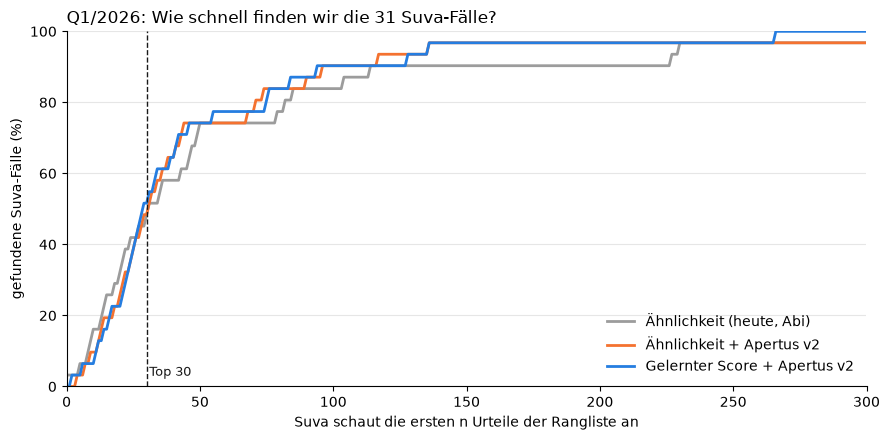

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for name, color in [("A · Ähnlichkeit (heute, Abi)", GRAY), ("C · Ähnlichkeit + Apertus v2", ORANGE),
                    ("F · Gelernter Score + Apertus v2", BLUE)]:
    curve = recall_curve(variants[name], 300)
    ax.plot(curve.index, curve.values * 100, color=color, linewidth=2, label=name[4:])
ax.axvline(30, color=INK, linewidth=1, linestyle="--")
ax.text(31, 3, "Top 30", fontsize=9, color=INK)
ax.set_xlabel("Suva schaut die ersten n Urteile der Rangliste an")
ax.set_ylabel("gefundene Suva-Fälle (%)")
ax.set_ylim(0, 100)
ax.set_xlim(0, 300)
ax.grid(axis="y", color="#e6e6e6")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower right")
ax.set_title("Q1/2026: Wie schnell finden wir die 31 Suva-Fälle?", loc="left")
fig.tight_layout()
plt.show()

In [10]:
# Welche Ränge bekommen die Suva-Fälle? (je kleiner, desto besser)
suva_ranks = pd.DataFrame({name[:1]: f[f.is_reference].set_index("case_id")["rank"] for name, f in variants.items()})
suva_ranks.describe().loc[["50%", "75%", "max"]].rename(index={"50%": "Median-Rang", "75%": "75 %-Rang", "max": "schlechtester Rang"}).round(0)

,A,B,C,D,E,F
Median-Rang,31.0,31.0,31.0,45.0,30.0,29.0
75 %-Rang,64.0,48.0,56.0,72.0,63.0,50.0
schlechtester Rang,1847.0,1847.0,1847.0,1847.0,243.0,266.0


## 5. Und Boost/Buff?

Mit dem gelernten Score ist ein Klick einfach **ein neues Beispiel fürs Training** (Suva-Fall ja/nein). Neu trainiert ist in 1 Sekunde.
Gleiche Klicks wie in Notebook 02: Buff auf `8C_221/2025` (Fehlalarm aus Q4), Boost auf `9C_406/2025` (IV-Urteil aus Q4).


In [11]:
meta = corpus.meta
buff_key = meta.index[meta.case_id == "8C_221/2025"][0]
boost_key = meta.index[meta.case_id == "9C_406/2025"][0]
base = learned_q1.set_index("doc_key")
threshold = base[base.is_reference].score.sort_values(ascending=False).iloc[22]   # Schwelle, bei der heute 23 Suva-Fälle darüber liegen

def click(**kw):
    after = learned_scores(corpus, date_from=Q1["date_from"], date_to=Q1["date_to"], **kw).set_index("doc_key")
    key = (kw.get("extra_negative") or kw.get("extra_positive"))[0]
    delta = after.score - base.score
    same = base.subject.map(subject_area) == subject_area(meta.at[key, "subject"])
    return {"Ø Änderung gleiches Rechtsgebiet": delta[same].mean(), "Ø Änderung übrige": delta[~same].mean(),
            "grösste Änderung eines Urteils": delta.abs().max(), "Urteile mit > 1 Punkt Änderung": int((delta.abs() > 1).sum()),
            "Suva-Fälle über Schwelle (vorher → nachher)":
                f"{int((base.is_reference & (base.score >= threshold)).sum())} → {int((after.is_reference & (after.score >= threshold)).sum())}"}

pd.DataFrame({"Buff 8C_221/2025": click(extra_negative=(buff_key,)),
              "Boost 9C_406/2025": click(extra_positive=(boost_key,))}).T.round(2)

,Ø Änderung gleiches Rechtsgebiet,Ø Änderung übrige,grösste Änderung eines Urteils,Urteile mit > 1 Punkt Änderung,Suva-Fälle über Schwelle (vorher → nachher)
Buff 8C_221/2025,0.0,0.0,0.0,0,23 → 23
Boost 9C_406/2025,1.273,0.135,29.915,260,23 → 22


**Lesart**
- **Buff ändert nichts**, und das ist richtig so: Im gelernten Modell zählt jedes Urteil, das Suva nicht zusammengefasst hat, bereits als „nicht relevant“.
  Ein Buff sagt dem Modell nichts Neues. Wirkung hat er nur für das **angeklickte Urteil selbst**, also sofort in der UI unter die Schwelle schieben.
- **Boost wirkt**, im gleichen Rechtsgebiet im Schnitt stärker als im Rest. Ein einzelnes Beispiel unter rund 4000 bewegt aber **einzelne Urteile stark und zufällig** (bis etwa 30 Punkte).
  Darum: Klicks sammeln und regelmässig neu trainieren, nicht nach jedem Klick die ganze Rangliste umstellen.


## 6. Fazit für das Team

| Frage | Antwort |
|---|---|
| Nur Ähnlichkeit oder Ähnlichkeit + Apertus? | **Kombination**, aber nur mit verbessertem Prompt. Auf Q4 (Prüfquartal) bringt Prompt v2 Top 30 von 61 % auf 71 % und Top 100 von 86 % auf 96 %. Auf Q1 ist der Gewinn kleiner: Top 100 von 84 % auf 90 %, für 90 % Recall 96 statt 114 Urteile, Top 30 unverändert. Mit dem heutigen Prompt v1 lehnt Apertus alle Suva-Fälle zur Invalidenversicherung ab. **Nur Apertus** ist für die Rangliste am schlechtesten, weil die Abstufung zu grob ist. |
| Wie bekommen Suva-Fälle einen hohen Score? | **1. Aus Suvas Entscheidungen lernen** statt nur Ähnlichkeit messen: Alle 31 Suva-Fälle stecken in den Top 243 statt Top 1847, die IV-Fälle rücken weit nach vorne. **2. Prompt v2:** IV mit UVG-Bezug als relevant definieren und die Skala erklären. **3. Beides kombinieren (F):** für 90 % Recall reichen 94 statt 114 Urteile. **Die Top 30 bleiben schwierig:** 15 bis 16 von 31 Suva-Fälle in allen Varianten. |
| Boost/Buff? | Sofort-Effekt nur auf das angeklickte Urteil (über bzw. unter die Schwelle). Lerneffekt: Klick = Trainingsbeispiel, regelmässig neu trainieren. Buff braucht man fürs Lernen kaum, „nicht zusammengefasst“ ist schon das Standard-Label. |

**Vorschlag für die Pipeline**
1. Stufe 1: **gelernter Score** über alle Urteile des Zeitraums (gratis), Vorauswahl der Top 200.
2. Stufe 2: **Apertus mit Prompt v2** nur für die Vorauswahl (etwa 200 Aufrufe à 1 s), Begründung für die UI kommt gleich mit.
3. Rangliste nach 0.5 × Apertus + 0.5 × Stufe 1 (Perzentil). Relevanz-Schwelle aus dem Sweep dieser Rangliste.

**Grenzen (bitte so im Report nennen)**
- Ein Testquartal mit 31 Suva-Fällen: Ein Fall entspricht etwa 3 Prozentpunkten Recall. Unterschiede von 1–2 Fällen sind nicht gesichert.
- Der gelernte Score konnte nicht auf Q4 geprüft werden, weil es vor Q4 keine Nicht-Suva-Urteile im Datenbestand gibt (Juli–Sept. 2025 enthält nur Suva-Fälle).
- Apertus 8B mit `temperature=0`. Das Gateway kann sich ändern, die Antworten liegen deshalb in `results/tables/apertus_*.jsonl`.
- Apertus hat nur die Vorauswahl gesehen. Ein Suva-Fall (`9C_65/2025`) liegt ausserhalb und wurde nie gefragt.
